# Analisis Data dan Prediksi Harga Parfum Wanita di eBay

Pada tugas ini, saya menggunakan dataset parfum wanita yang dijual di eBay. Saya mulai dengan membaca dan memeriksa datanya, lalu membersihkan data yang perlu diperbaiki. Setelah itu, saya melihat isi data melalui beberapa statistik dan grafik. Terakhir, saya membuat model untuk memperkirakan harga parfum.

Di sini, kolom `price` saya gunakan sebagai nilai yang ingin diprediksi. Untuk melihat hasil modelnya, saya menggunakan MAE, MSE, dan R². Hasilnya nanti menggambarkan performa model pada dataset ini, jadi belum tentu bisa mewakili harga semua parfum yang dijual di luar dataset.

## 1. Data loading

Pertama, saya membaca file CSV menggunakan pandas. Setelah itu, saya menampilkan beberapa baris awal dan melihat ukuran dataset. Dari sini, saya bisa mendapat gambaran awal tentang data yang akan digunakan sebelum masuk ke tahap berikutnya.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Membaca dataset
df = pd.read_csv("ebay_womens_perfume.csv")

print("Ukuran dataset:", df.shape)
display(df.head())
display(df.info())

Ukuran dataset: (1000, 10)


,brand,title,type,price,priceWithCurrency,available,availableText,sold,lastUpdated,itemLocation
0,Carolina Herrera,Good Girl by Carolina Herrera 2.7 oz Eau De Pa...,Eau de Parfum,43.99,US $43.99/ea,2.0,2 available / 393 sold,393.0,"May 23, 2024 10:43:50 PDT","Thomasville, Alabama, United States"
1,As Shown,Parfums de Marly Delina La Rosee Eau de Parfum...,Eau de Parfum,79.99,US $79.99,5.0,5 available / 40 sold,40.0,"May 24, 2024 00:15:48 PDT","New Jersey, Hong Kong"
2,PRADA,PRADA Paradoxe by Prada EDP 3.0oz/90ml Spray P...,Eau de Parfum,59.99,US $59.99,10.0,More than 10 available / 35 sold,35.0,"May 14, 2024 20:54:25 PDT","Orange, New Jersey, United States"
3,As Show,J'adore Parfum D'eau by Christian 3.4 oz EDP F...,Eau de Parfum,59.99,US $59.99/ea,10.0,More than 10 available / 9 sold,9.0,"May 23, 2024 01:23:05 PDT","USA, New Jersey, Hong Kong"
4,Khadlaj,Shiyaaka for Men EDP Spray 100ML (3.4 FL.OZ) B...,Eau de Parfum,29.99,US $29.99/ea,10.0,More than 10 available,NaN,NaN,"Little Ferry, New Jersey, United States"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   brand              999 non-null    object 
 1   title              1000 non-null   object 
 2   type               998 non-null    object 
 3   price              1000 non-null   float64
 4   priceWithCurrency  1000 non-null   object 
 5   available          869 non-null    float64
 6   availableText      992 non-null    object 
 7   sold               984 non-null    float64
 8   lastUpdated        927 non-null    object 
 9   itemLocation       1000 non-null   object 
dtypes: float64(3), object(7)
memory usage: 78.3+ KB


None

## 2. Data cleaning

Sebelum lanjut ke analisis, saya memeriksa apakah ada data yang kosong atau baris yang tercatat lebih dari satu kali. Baris duplikat kemudian saya hapus supaya data yang sama tidak dihitung berulang. Saya juga memastikan kolom harga dan kolom angka lainnya memiliki format yang sesuai.

Karena `price` adalah nilai yang akan diprediksi, baris yang tidak memiliki harga tidak digunakan dalam pemodelan. Sementara itu, nilai kosong pada kolom lain ditangani saat menyiapkan data untuk model. Jadi, baris tidak langsung dihapus hanya karena ada kolom lain yang kosong.

In [2]:
# Melihat ringkasan nilai kosong dan duplikat
print("Nilai kosong per kolom:")
display(df.isna().sum().sort_values(ascending=False))
print("Jumlah baris duplikat:", df.duplicated().sum())

# Menghapus baris duplikat
df = df.drop_duplicates().copy()

# Mengubah kolom numerik yang diperlukan menjadi format angka
for col in ["price", "available", "sold"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Harga adalah target, jadi baris tanpa harga dihapus
df = df.dropna(subset=["price"]).copy()

# Kolom dengan banyak detail teks atau informasi yang mirip dengan harga tidak dipakai.
# priceWithCurrency berisi informasi harga dalam format teks, sehingga dikeluarkan
# agar model hanya belajar dari fitur produk yang dipilih.
target = "price"
features = ["brand", "type", "available", "sold"]

print("Ukuran data setelah cleaning:", df.shape)
print("Kolom yang digunakan:", features)
print("Target:", target)
display(df[features + [target]].head())

Nilai kosong per kolom:


available            131
lastUpdated           73
sold                  16
availableText          8
type                   2
brand                  1
title                  0
price                  0
priceWithCurrency      0
itemLocation           0
dtype: int64

Jumlah baris duplikat: 1
Ukuran data setelah cleaning: (999, 10)
Kolom yang digunakan: ['brand', 'type', 'available', 'sold']
Target: price


,brand,type,available,sold,price
0,Carolina Herrera,Eau de Parfum,2.0,393.0,43.99
1,As Shown,Eau de Parfum,5.0,40.0,79.99
2,PRADA,Eau de Parfum,10.0,35.0,59.99
3,As Show,Eau de Parfum,10.0,9.0,59.99
4,Khadlaj,Eau de Parfum,10.0,NaN,29.99


## 3. Exploratory Data Analysis (EDA)

Setelah data dibersihkan, saya lanjut melihat isi data lebih dekat supaya tahu gambaran harga parfum yang ada di dataset. Saya mulai dari statistik dasar, lalu melihat beberapa grafik: sebaran harga, merek yang paling sering muncul, median harga dari beberapa merek, dan hubungan antara harga dengan jumlah produk yang terjual.

Menurut saya, tahap ini penting karena dari sini saya bisa melihat pola awal sebelum menentukan model yang akan digunakan. Saya juga tidak langsung menganggap pola pada grafik sebagai penyebab suatu hal, karena grafik hanya membantu menunjukkan gambaran hubungan dalam data.

,price,available,sold
count,999.000000,868.000000,983.000000
mean,39.884865,21.447005,497.826043
std,29.085615,51.502977,1373.117784
min,1.990000,2.000000,1.000000
25%,20.690000,6.000000,15.000000
50%,32.990000,10.000000,52.000000
75%,49.990000,10.000000,264.500000
max,299.990000,557.000000,17854.000000


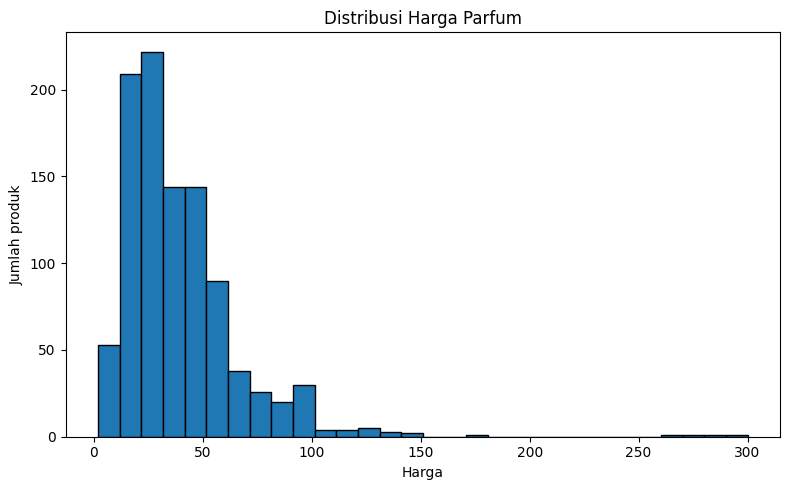

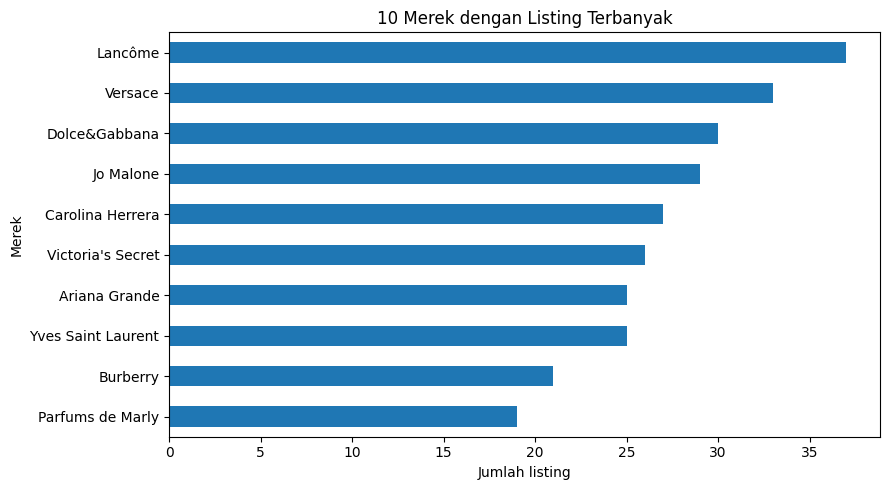

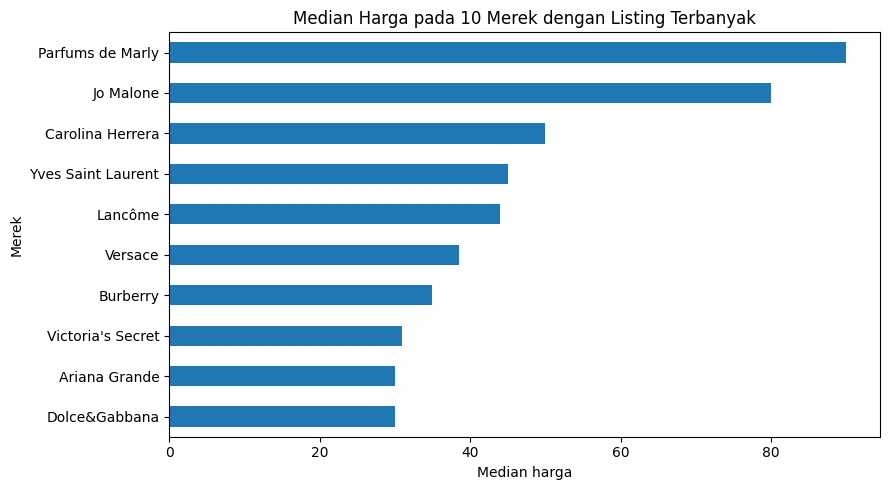

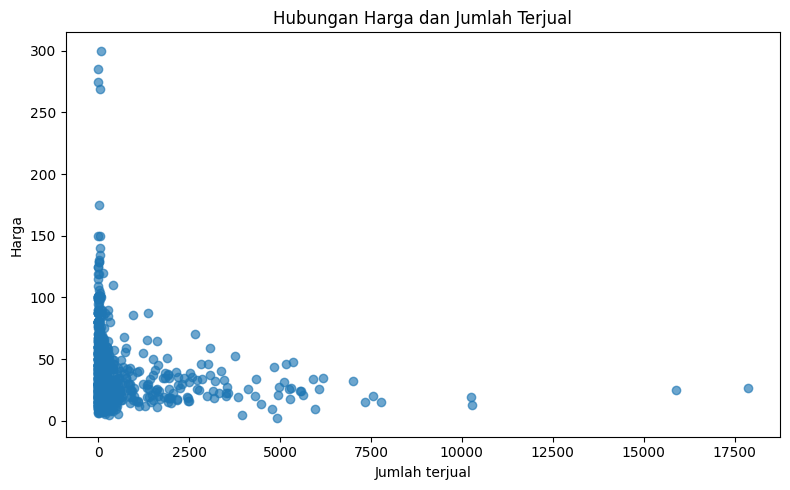

In [3]:
# Statistik deskriptif untuk kolom numerik
display(df[["price", "available", "sold"]].describe())

# Distribusi harga
plt.figure(figsize=(8, 5))
plt.hist(df["price"], bins=30, edgecolor="black")
plt.title("Distribusi Harga Parfum")
plt.xlabel("Harga")
plt.ylabel("Jumlah produk")
plt.tight_layout()
plt.show()

# 10 merek dengan jumlah listing terbanyak
top_brands = df["brand"].fillna("Tidak diketahui").value_counts().head(10)
plt.figure(figsize=(9, 5))
top_brands.sort_values().plot(kind="barh")
plt.title("10 Merek dengan Listing Terbanyak")
plt.xlabel("Jumlah listing")
plt.ylabel("Merek")
plt.tight_layout()
plt.show()

# Harga median untuk merek dengan listing terbanyak
brands_for_plot = top_brands.index
brand_prices = (df[df["brand"].fillna("Tidak diketahui").isin(brands_for_plot)]
                .assign(brand_clean=lambda x: x["brand"].fillna("Tidak diketahui"))
                .groupby("brand_clean")["price"].median()
                .sort_values())
plt.figure(figsize=(9, 5))
brand_prices.plot(kind="barh")
plt.title("Median Harga pada 10 Merek dengan Listing Terbanyak")
plt.xlabel("Median harga")
plt.ylabel("Merek")
plt.tight_layout()
plt.show()

# Hubungan harga dan jumlah terjual
plt.figure(figsize=(8, 5))
plt.scatter(df["sold"], df["price"], alpha=0.65)
plt.title("Hubungan Harga dan Jumlah Terjual")
plt.xlabel("Jumlah terjual")
plt.ylabel("Harga")
plt.tight_layout()
plt.show()

### Pembahasan hasil EDA

Dari statistik deskriptif, harga parfum memiliki nilai rata-rata sekitar **39,89**, sedangkan nilai mediannya **32,99**. Rata-rata yang lebih tinggi daripada median menunjukkan bahwa ada beberapa produk dengan harga cukup tinggi yang ikut menaikkan nilai rata-rata. Harga paling rendah pada dataset ini adalah **1,99**, sementara harga tertingginya **299,99**.

Pada grafik distribusi harga, harga produk terlihat tidak tersebar secara merata. Sebagian besar harga berada di rentang yang lebih rendah, sementara hanya sebagian kecil produk yang memiliki harga jauh lebih tinggi. Hal ini sejalan dengan perbedaan antara nilai rata-rata dan median tadi.

Dari grafik 10 merek dengan listing terbanyak, **Lancôme** muncul paling sering, yaitu sebanyak 37 listing, disusul **Versace** sebanyak 33 listing dan **Dolce&Gabbana** sebanyak 30 listing. Angka ini menunjukkan jumlah listing yang tercatat dalam dataset, bukan berarti merek tersebut pasti paling laku di seluruh eBay.

Grafik median harga digunakan untuk membandingkan harga tengah dari merek-merek yang listing-nya paling banyak. Saya memilih median karena nilai ini tidak terlalu mudah terpengaruh oleh beberapa harga yang sangat tinggi. Dari grafik tersebut, kita bisa melihat bahwa harga tengah antar-merek tidak selalu sama.

Terakhir, pada grafik harga dan jumlah terjual, titik-titik data tersebar dan tidak membentuk pola naik yang kuat. Korelasi antara harga dan jumlah terjual pada data ini sekitar **-0,14**, yang menunjukkan hubungan negatif yang lemah. Jadi, dari dataset ini saja belum terlihat bahwa harga yang lebih tinggi selalu diikuti jumlah penjualan yang lebih rendah secara kuat. Hasil EDA ini menjadi gambaran awal sebelum data digunakan untuk membuat model prediksi.

## 4. Menyiapkan fitur dan membagi dataset

Untuk percobaan ini, saya menggunakan kolom `brand`, `type`, `available`, dan `sold` sebagai fitur untuk memprediksi `price`. Karena `brand` dan `type` berisi kategori, nilainya perlu diubah ke bentuk yang dapat diproses oleh model. Nilai kosong juga ditangani sesuai jenis kolomnya, baik kategori maupun angka.

Selanjutnya, dataset dibagi menjadi 80% data train dan 20% data test. Data train digunakan untuk melatih model, sedangkan data test digunakan untuk melihat hasil prediksi pada data yang tidak dipakai saat pelatihan.

In [4]:
X = df[features].copy()
y = df[target].copy()

categorical_features = ["brand", "type"]
numeric_features = ["available", "sold"]

# Pipeline untuk kategori dan numerik
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor = ColumnTransformer(transformers=[
    ("cat", categorical_pipeline, categorical_features),
    ("num", numeric_pipeline, numeric_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Jumlah data train:", X_train.shape[0])
print("Jumlah data test:", X_test.shape[0])

Jumlah data train: 799
Jumlah data test: 200


## 5. Modeling

Pada tahap pemodelan, saya menggunakan **Random Forest Regressor** untuk memperkirakan harga parfum. Model ini menggabungkan hasil dari beberapa pohon keputusan untuk menghasilkan prediksi.

Proses persiapan data dan model saya susun dalam satu pipeline. Dengan begitu, pengisian nilai kosong dan pengubahan data kategori dilakukan sebagai bagian dari proses pemodelan. Model kemudian dilatih menggunakan data train yang sudah disiapkan.

In [5]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        min_samples_leaf=2
    ))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Model selesai dilatih.")

Model selesai dilatih.


## 6. Evaluasi model: MAE, MSE, dan R²

Setelah model dilatih, saya menggunakannya untuk memprediksi harga pada data test. Hasil prediksi tersebut lalu dibandingkan dengan harga sebenarnya menggunakan tiga metrik berikut.

- **MAE** menunjukkan rata-rata selisih antara harga sebenarnya dan harga prediksi. Semakin kecil nilainya, semakin kecil rata-rata kesalahan prediksinya.
- **MSE** menghitung rata-rata kesalahan yang sudah dikuadratkan. Karena itu, kesalahan prediksi yang besar akan lebih berpengaruh pada nilai MSE.
- **R²** menunjukkan seberapa baik model menjelaskan variasi harga pada data test. Nilai yang mendekati 1 biasanya menunjukkan hasil yang lebih baik. Jika nilainya negatif, performa model bahkan lebih buruk dibandingkan jika prediksi hanya menggunakan rata-rata harga sebagai patokan.

Ketiga nilai ini saya lihat bersama-sama supaya hasil evaluasi model bisa dipahami dengan lebih jelas.

In [6]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

metrics = pd.DataFrame({
    "Metrik": ["MAE", "MSE", "R²"],
    "Nilai": [mae, mse, r2]
})
display(metrics)

print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"R²: {r2:.4f}")

,Metrik,Nilai
0,MAE,16.977489
1,MSE,757.803001
2,R²,0.113276


MAE: 16.9775
MSE: 757.8030
R²: 0.1133


## 7. Membandingkan harga sebenarnya dan hasil prediksi

Di bagian ini, saya melihat beberapa contoh harga sebenarnya dan harga yang diprediksi oleh model. Saya juga menampilkan grafik untuk membandingkan keduanya. Jika titik-titik pada grafik berada dekat dengan garis diagonal, berarti prediksi model cukup dekat dengan harga sebenarnya. Jika titiknya jauh dari garis, berarti selisih prediksinya lebih besar.

,Harga aktual,Harga prediksi
0,24.95,25.506818
1,33.75,52.683472
2,52.78,29.655692
3,9.99,33.355902
4,21.90,50.513639
5,45.99,29.511570
6,11.49,47.146210
7,19.54,27.991613
8,34.43,29.378772
9,27.50,60.338906


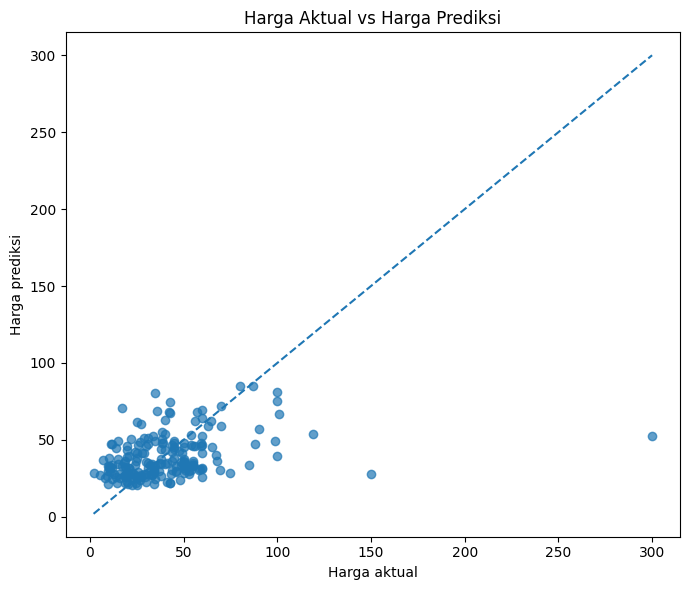

In [7]:
comparison = pd.DataFrame({
    "Harga aktual": y_test.values,
    "Harga prediksi": y_pred
})
display(comparison.head(10))

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.7)
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
plt.title("Harga Aktual vs Harga Prediksi")
plt.xlabel("Harga aktual")
plt.ylabel("Harga prediksi")
plt.tight_layout()
plt.show()

## 8. Kesimpulan

Dari tugas ini, saya sudah melakukan beberapa tahap pengolahan data parfum wanita dari eBay, mulai dari membaca dan membersihkan data, melihat pola melalui EDA, membagi data menjadi train dan test, sampai membuat model Random Forest Regressor untuk memprediksi harga.

Untuk mengetahui hasil model, saya menggunakan MAE, MSE, dan R². MAE menunjukkan rata-rata selisih prediksi, MSE memberi penalti lebih besar pada kesalahan yang jauh, sedangkan R² membantu melihat seberapa baik model menjelaskan variasi harga pada data test. Hasil akhirnya perlu dilihat berdasarkan nilai yang diperoleh saat notebook dijalankan.

Menurut saya, analisis ini masih bisa dikembangkan, misalnya dengan mencoba fitur lain yang tersedia atau membandingkan hasil Random Forest dengan model lain. Hasil prediksi juga tetap bergantung pada data yang digunakan, jadi model ini belum tentu menghasilkan tingkat akurasi yang sama jika diterapkan pada dataset yang berbeda.